# 9.1 Supplementary Activity: Build, Train and Evaluate a Custom Deep Learning Model

**Course:** Machine Learning · **Module:** 9.1 TensorFlow Fundamentals (supplementary)
**Estimated time:** 2–3 hours · **Work mode:** individual or pairs

### Intended Learning Outcome
> **Design and implement a custom deep learning model using TensorFlow APIs, and evaluate its performance for a real-world predictive task.**

### Scenario
A hospital's pathology unit wants a **decision-support model** that flags breast tumours as **malignant** or **benign** using 30 measurements computed from a digitised fine-needle aspirate (FNA) image of a breast mass. Doctors will review every flagged case. **Missing a malignant tumour (a false negative) is far more costly than a false alarm.**

Your job is to:
1. **Prepare** the data without leaking information from the test set.
2. **Design** your own deep learning model, a multilayer perceptron (MLP) built with `tf.keras.Sequential`, and justify each choice.
3. **Train** it with sensible callbacks and diagnose over- or underfitting.
4. **Evaluate** it honestly against baselines, using metrics that fit the scenario, and **tune the decision threshold** for high recall.
5. **Experiment**, **save** the model, and **reflect** on the results.

### TensorFlow APIs you will use
`tf.data.Dataset` · `tf.keras.layers.Normalization` · `tf.keras.Sequential` with `Dense` and `Dropout` layers · `tf.keras.metrics` · `tf.keras.callbacks.EarlyStopping` · `model.save` / `tf.keras.models.load_model`

### How to work
- Replace every `None` / `# TODO` with your own code. Run each **Check** cell: ✅ means you're on track.
- Run the notebook **top to bottom** (Runtime → Restart and run all) before you submit.
- A GPU is **not** required. The dataset is small and trains in seconds on CPU.

### Deliverables
1. This notebook, fully executed, with the **Model Design Card** (Part D) and the **Reflection** (Part I) completed.
2. Your saved model file, `cancernet.keras` (Part H).


## Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             accuracy_score, precision_score, recall_score)

import warnings
warnings.filterwarnings("ignore", message=".*shuffle=True.*")  # harmless Keras notice when fitting on a tf.data pipeline

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow together

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: False


---
## Part A: Understand the data

The **Breast Cancer Wisconsin (Diagnostic)** dataset ships with scikit-learn, so no download is needed. Each row is one tumour; the 30 features describe the cell nuclei: radius, texture, perimeter, area, smoothness and so on, each as a mean, standard error and "worst" value.

In [3]:
data = load_breast_cancer(as_frame=True)
df = data.frame

print("Shape:", df.shape)
print("Target names:", list(data.target_names), "->", "0 = malignant, 1 = benign (scikit-learn's encoding)")
df.head()

Shape: (569, 31)
Target names: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign (scikit-learn's encoding)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
# Feature scales differ by orders of magnitude, so we must normalise
df.drop(columns="target").describe().T[["mean", "std", "min", "max"]].sort_values("max", ascending=False).head(8)

,mean,std,min,max
worst area,880.583128,569.356993,185.200,4254.00
mean area,654.889104,351.914129,143.500,2501.00
area error,40.337079,45.491006,6.802,542.20
worst perimeter,107.261213,33.602542,50.410,251.20
mean perimeter,91.969033,24.298981,43.790,188.50
worst texture,25.677223,6.146258,12.020,49.54
mean texture,19.289649,4.301036,9.710,39.28
worst radius,16.269190,4.833242,7.930,36.04


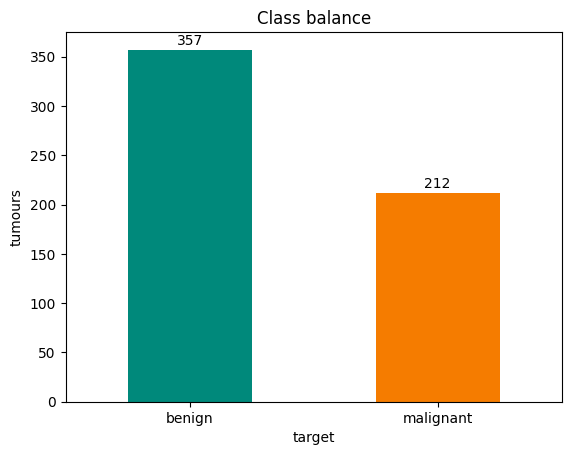

In [5]:
counts = df["target"].map({0: "malignant", 1: "benign"}).value_counts()
ax = counts.plot(kind="bar", color=["#00897B", "#F57C00"], rot=0, title="Class balance")
ax.set_ylabel("tumours")
for i, v in enumerate(counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.show()

### Task A1: Encode the target so the positive class is **malignant**
scikit-learn uses `0 = malignant`. Our scenario cares about **detecting malignancy**, so precision and recall should refer to malignant tumours. Flip the labels so that **`1 = malignant`** and **`0 = benign`**.

Create:
- `X`: a `float32` NumPy array of the 30 features, with shape `(569, 30)`
- `y`: a `float32` NumPy array of labels, with `1 = malignant`

In [6]:
X = df.drop(columns="target").values.astype("float32")  # TODO: all columns except "target", as float32
y = (1 - df["target"]).values.astype("float32")  # TODO: flip the labels so 1 = malignant, as float32

X.shape, y.mean()

((569, 30), np.float32(0.37258348))

In [7]:
# Check
assert X.shape == (569, 30), "X should have shape (569, 30)"
assert X.dtype == np.float32 and y.dtype == np.float32, "use float32"
assert abs(y.sum() - 212) < 1e-6, "there are 212 malignant tumours, so y should sum to 212"
print("✅ A1 passed: 212 malignant (1), 357 benign (0)")

✅ A1 passed: 212 malignant (1), 357 benign (0)


---
## Part B: Prepare the data

### Task B1: Stratified train / validation / test split (60 / 20 / 20)
- **Train**: fits the weights. **Validation**: guides design choices, early stopping and threshold tuning. **Test**: touched **once**, for the final report.
- Use `stratify=` so every split keeps the same malignant/benign ratio, and `random_state=SEED`.

> 💡 Split twice: first 80/20 into (train_full, test), then split train_full 75/25 into (train, val).

In [8]:
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=SEED)

print(f"train: {len(X_train)}  val: {len(X_val)}  test: {len(X_test)}")

train: 341  val: 114  test: 114


In [9]:
# Check
assert (len(X_train), len(X_val), len(X_test)) == (341, 114, 114), "expected 341 / 114 / 114"
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    assert abs(part.mean() - y.mean()) < 0.02, f"{name} split is not stratified"
print("✅ B1 passed: stratified 60/20/20 split")

✅ B1 passed: stratified 60/20/20 split


### Task B2: A normalisation layer fitted on the **training data only**
`tf.keras.layers.Normalization` learns each feature's mean and variance with `.adapt()`. Putting it **inside** the model means the saved model accepts raw measurements, so no separate scaler is needed at deployment.

Complete `make_normalizer()` so it returns a `Normalization` layer adapted on `X_train`.

> ⚠️ Adapting on `X` (all data) leaks test-set statistics into training. That's a classic data-leakage bug.

In [10]:
def make_normalizer():
    norm = tf.keras.layers.Normalization(axis=1)  # TODO: create a tf.keras.layers.Normalization layer
    norm.adapt(X_train)
    return norm

normalizer = make_normalizer()
z = normalizer(X_train).numpy()
print("mean ≈", z.mean().round(3), " std ≈", z.std().round(3))

mean ≈ 0.0  std ≈ 1.0


In [11]:
# Check
assert np.allclose(z.mean(axis=0), 0, atol=1e-3) and np.allclose(z.std(axis=0), 1, atol=1e-2), \
    "after normalising, each training feature should have mean 0 and std 1"
print("✅ B2 passed: normaliser fitted on training data")

✅ B2 passed: normaliser fitted on training data


### Task B3: Build `tf.data` pipelines
Create `train_ds`, `val_ds` and `test_ds` from `(features, labels)` pairs.
- **Shuffle only the training set** (`seed=SEED`), then batch with `BATCH_SIZE`.
- Add `.prefetch(tf.data.AUTOTUNE)` so batches are prepared while the model trains.

In [12]:
BATCH_SIZE = 32

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(buffer_size=len(X_train), seed=SEED)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

train_ds.element_spec

(TensorSpec(shape=(None, 30), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.float32, name=None))

In [13]:
# Check
xb, yb = next(iter(train_ds))
assert xb.shape == (BATCH_SIZE, 30) and yb.shape == (BATCH_SIZE,), "batches should be (32, 30) features and (32,) labels"
assert sum(1 for _ in test_ds.unbatch()) == 114, "test_ds should contain all 114 test samples"
print("✅ B3 passed: pipelines ready")

✅ B3 passed: pipelines ready


---
## Part C: Baselines (what are we trying to beat?)

A model is only "good" relative to something. We use two reference points:
1. **Majority class:** always predict "benign". This shows what accuracy alone can hide.
2. **Logistic regression in Keras:** a single `Dense(1, sigmoid)` unit, the simplest neural network.

Run the helpers below; you'll reuse them for every model.

In [14]:
def make_metrics():
    """Fresh metric objects for each model (metric objects keep state, so don't share them)."""
    return [tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")]


def summarize(name, y_true, y_prob, threshold=0.5):
    """Test-set summary at a given decision threshold (positive class = malignant)."""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_prob)) > 1 else 0.5
    return {"model": name, "threshold": round(threshold, 3),
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "AUC": auc, "false_neg": int(fn), "false_pos": int(fp)}

### Task C1: Majority-class baseline
Compute the test accuracy you would get by **always predicting benign (0)**. Then use `summarize()` to see its recall.

In [15]:
majority_prob = np.zeros_like(y_test)  # TODO: an array of zeros, one per test sample
majority_summary = summarize("Majority class (always benign)", y_test, majority_prob)
majority_summary

{'model': 'Majority class (always benign)',
 'threshold': 0.5,
 'accuracy': 0.631578947368421,
 'precision': 0.0,
 'recall': 0.0,
 'AUC': 0.5,
 'false_neg': 42,
 'false_pos': 0}

In [16]:
# Check
assert abs(majority_summary["accuracy"] - 0.6316) < 0.01 and majority_summary["recall"] == 0
print(f"✅ C1 passed: {majority_summary['accuracy']:.1%} accuracy, yet it misses every malignant tumour (recall = 0)")

✅ C1 passed: 63.2% accuracy, yet it misses every malignant tumour (recall = 0)


### Task C2: Logistic-regression baseline
Build a `Sequential` model: `Input(30)` → `make_normalizer()` → `Dense(1, activation="sigmoid")`.
Compile it with `Adam(learning_rate=1e-2)`, `binary_crossentropy` loss and `make_metrics()`, then train for 100 epochs.

In [17]:
baseline = tf.keras.Sequential([
    tf.keras.Input(shape=(30,)),
    make_normalizer(),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="logistic_baseline")

baseline.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-2),
    loss="binary_crossentropy",
    metrics=make_metrics()
)

baseline.fit(train_ds, validation_data=val_ds, epochs=100, verbose=0)

baseline_prob = baseline.predict(X_test, verbose=0).ravel()
baseline_summary = summarize("Logistic regression (Keras)", y_test, baseline_prob)
baseline_summary

{'model': 'Logistic regression (Keras)',
 'threshold': 0.5,
 'accuracy': 0.956140350877193,
 'precision': 0.9512195121951219,
 'recall': 0.9285714285714286,
 'AUC': np.float64(0.9940476190476191),
 'false_neg': 3,
 'false_pos': 2}

In [18]:
# Check
assert baseline.count_params() == 30 * 2 + 1 + 31, "normaliser (mean+var+count) + 30 weights + 1 bias"
assert baseline_summary["accuracy"] > 0.9, "a logistic baseline should exceed 90% accuracy here; check your training"
print(f"✅ C2 passed: the baseline already reaches {baseline_summary['accuracy']:.1%} accuracy. Your custom model must earn its complexity!")

✅ C2 passed: the baseline already reaches 95.6% accuracy. Your custom model must earn its complexity!


---
## Part D: Design your model

You'll build a **multilayer perceptron (MLP)** with `tf.keras.Sequential`: a stack of fully connected (`Dense`) layers. It's the simplest deep learning architecture, and it's the right tool for 30 tabular features. Your design decisions are **how many hidden layers, how many units in each, and how much dropout**.

```
features (30) → Normalization → Dense (ReLU) → Dropout → Dense (ReLU) → Dropout → Dense(1, sigmoid) = P(malignant)
```

### Task D1: Build your MLP
Complete the `Sequential` model:
- It starts with `tf.keras.Input(shape=(30,))` and `make_normalizer()` (done for you), so the model accepts raw measurements.
- Add **at least two** hidden `Dense` layers with `activation="relu"`, each followed by `Dropout`. You choose the units and the dropout rate; 64 → 32 units with dropout 0.3 is a good start.
- Finish with **`Dense(1, activation="sigmoid")`**: one unit because this is a yes/no problem, and the sigmoid turns its output into P(malignant).

> 💡 Why not `Dense(2, activation="softmax")`? It would also work, but for two classes a single sigmoid unit is simpler and carries the same information.

In [19]:
tf.keras.utils.set_random_seed(SEED)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(30,)),
    make_normalizer(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3), # TODO: hidden Dense layer (ReLU), then Dropout
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3), # TODO: hidden Dense layer (ReLU), then Dropout
    tf.keras.layers.Dense(1, activation="sigmoid"),# TODO: output layer: Dense(1, sigmoid)
], name="cancernet")

model.summary()

Model: "cancernet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 30)             │            61 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,158 (16.25 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 61 (248.00 B)

In [20]:
# Check
_dense = [l for l in model.layers if isinstance(l, tf.keras.layers.Dense)]
assert isinstance(model.layers[0], tf.keras.layers.Normalization), "the first layer should be the normaliser"
assert len(_dense) >= 3, "use at least two hidden Dense layers plus the output layer"
assert all(l.activation.__name__ == "relu" for l in _dense[:-1]), "hidden layers should use ReLU"
assert _dense[-1].units == 1 and _dense[-1].activation.__name__ == "sigmoid", "the output should be Dense(1, activation='sigmoid')"
assert any(isinstance(l, tf.keras.layers.Dropout) for l in model.layers), "add Dropout after your hidden layers"
print(f"✅ D1 passed: MLP with {len(_dense) - 1} hidden layers and {model.count_params():,} parameters")

✅ D1 passed: MLP with 2 hidden layers and 4,158 parameters


### Task D2: Model Design Card
Fill in the table, then justify each choice in **one or two sentences**.

| Design decision | Your choice | Justification |
|---|---|---|
| Number of hidden layers and units | | |
| Hidden-layer activation | | |
| Regularisation (dropout rate, early stopping) | | |
| Output activation and loss | | |
| Optimiser and learning rate | | |
| **Priority metric** for this scenario | | |

---
## Part E: Train the model

### Task E1: Compile and fit
- Compile your `model` from D1 with optimiser `Adam(learning_rate=1e-3)`, loss `BinaryCrossentropy()` and metrics `make_metrics()`.
- Callback: `EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)`.
- Train for up to **300 epochs** on `train_ds`, validating on `val_ds`, and keep the returned `history`.

In [21]:
# Compile model with Adam optimizer, binary crossentropy, and the custom metrics
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=make_metrics()
)

# Configure early stopping to monitor validation loss and restore the best weights
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

# Fit the model and capture the history
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=300,
    callbacks=[early_stop],
    verbose=0
)

print("Trained for", len(history.history["loss"]), "epochs")

Trained for 41 epochs


In [22]:
# Check
assert history is not None and "val_auc" in history.history, "train with validation_data and make_metrics()"
assert len(history.history["loss"]) < 300, "EarlyStopping should stop training before 300 epochs"
print(f"✅ E1 passed: best val_loss = {min(history.history['val_loss']):.4f}")

✅ E1 passed: best val_loss = 0.0648


### Task E2: Plot and interpret the learning curves (run the cell, then answer below)

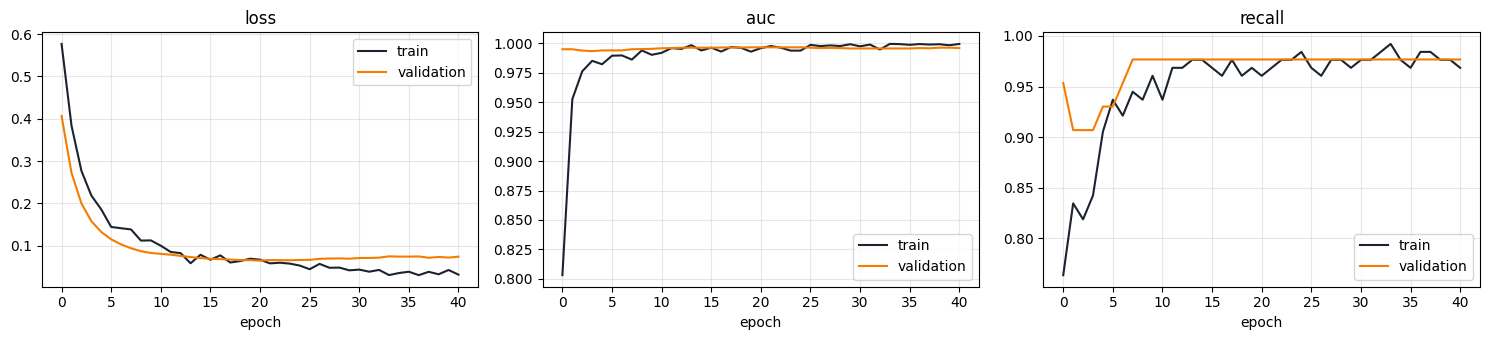

In [23]:
def plot_history(history, metrics=("loss", "auc", "recall")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.5))
    for ax, m in zip(axes, metrics):
        ax.plot(history.history[m], label="train", color="#1B2330")
        ax.plot(history.history[f"val_{m}"], label="validation", color="#F57C00")
        ax.set_title(m); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

plot_history(history)

**E2. Interpretation:** Is the model overfitting, underfitting or well fitted? Point to specific evidence in the curves (e.g. the gap between train and validation loss, or where validation loss stops improving).

The MLP model seems to be well-fitted. The validation loss of the model decreases steadily and stabilizes alongside the training loss, and does not show a U-shape that indicates overfitting. The dropout layers also prevented the model from memorizing the training subset.

---
## Part F: Evaluate the model

### Task F1: Test-set metrics at the default threshold (0.5)
Get predicted probabilities for `X_test`, then use `summarize()`.

In [24]:
custom_prob = model.predict(X_test, verbose=0).ravel()  # model.predict(...) flattened to 1-D
custom_summary = summarize("CancerNet (MLP) @0.5", y_test, custom_prob)
custom_summary

{'model': 'CancerNet (MLP) @0.5',
 'threshold': 0.5,
 'accuracy': 0.9824561403508771,
 'precision': 0.9761904761904762,
 'recall': 0.9761904761904762,
 'AUC': np.float64(0.9973544973544974),
 'false_neg': 1,
 'false_pos': 1}

In [25]:
# Check
assert custom_prob.shape == (114,), "flatten predictions with .ravel()"
assert custom_summary["AUC"] > 0.95, "test AUC should exceed 0.95; revisit your model or training"
print(f"✅ F1 passed: test AUC = {custom_summary['AUC']:.3f}")

✅ F1 passed: test AUC = 0.997


### Task F2: Confusion matrix and classification report (run and read)

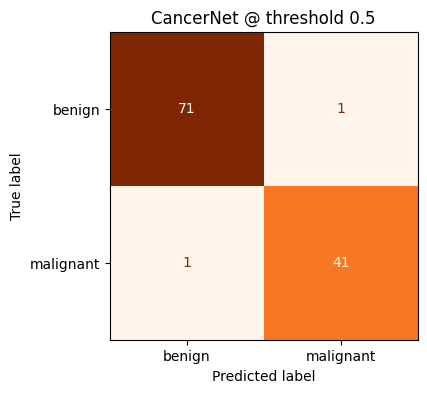

              precision    recall  f1-score   support

      benign      0.986     0.986     0.986        72
   malignant      0.976     0.976     0.976        42

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



In [26]:
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (custom_prob >= 0.5).astype(int),
                                        display_labels=["benign", "malignant"],
                                        cmap="Oranges", colorbar=False, ax=ax)
ax.set_title("CancerNet @ threshold 0.5"); plt.show()

print(classification_report(y_test, (custom_prob >= 0.5).astype(int), target_names=["benign", "malignant"], digits=3))

### Task F3: ROC curves: custom model vs logistic baseline (run and read)

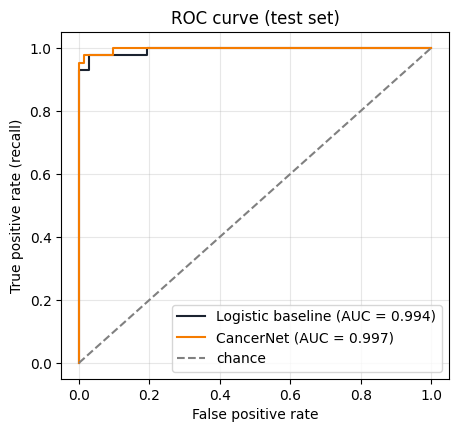

In [27]:
plt.figure(figsize=(5, 4.5))
for name, prob, color in [("Logistic baseline", baseline_prob, "#1B2330"), ("CancerNet", custom_prob, "#F57C00")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})", color=color)
plt.plot([0, 1], [0, 1], "--", color="grey", label="chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curve (test set)"); plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.show()

### Task F4: Tune the decision threshold for the clinical goal, using validation data
The default threshold of 0.5 treats both errors as equally bad, but a missed malignancy is the worst error here. The pathology unit's policy is:

> **Catch as many malignant tumours as possible, as long as at least 90% of flagged cases are truly malignant** (so doctors aren't flooded with false alarms).

Recall can only go up as the threshold goes down, so this means: pick the **lowest threshold** whose **validation precision** is at least `MIN_PRECISION`.

> ⚠️ Tune on **validation**, never on test. Choosing a threshold by peeking at test results makes the test score optimistic.

> 💡 `precision_recall_curve` returns arrays where `precision[i]` corresponds to `thresholds[i]` (ignore the last precision value).

In [28]:
MIN_PRECISION = 0.90

val_prob = model.predict(X_val, verbose=0).ravel()  # predicted probabilities on X_val (1-D)
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)

# Find thresholds where validation precision is at least MIN_PRECISION
valid_thresholds = thresholds[precision[:-1] >= MIN_PRECISION]
best_threshold = valid_thresholds[0]  # Grab the lowest threshold that meets the criteria
print(f"Chosen threshold: {best_threshold:.3f}")

tuned_summary = summarize(f"CancerNet @tuned", y_test, custom_prob, threshold=float(best_threshold))
tuned_summary

Chosen threshold: 0.320


{'model': 'CancerNet @tuned',
 'threshold': 0.32,
 'accuracy': 0.9736842105263158,
 'precision': 0.9534883720930233,
 'recall': 0.9761904761904762,
 'AUC': np.float64(0.9973544973544974),
 'false_neg': 1,
 'false_pos': 2}

In [29]:
# Check
_yp = (val_prob >= best_threshold).astype(int)
_val_prec, _val_rec = precision_score(y_val, _yp), recall_score(y_val, _yp)
assert _val_prec >= MIN_PRECISION, "the chosen threshold must keep validation precision >= MIN_PRECISION"
assert not any(precision_score(y_val, (val_prob >= t).astype(int)) >= MIN_PRECISION for t in thresholds[thresholds < best_threshold]), \
    "pick the LOWEST threshold that meets the precision policy"
print(f"✅ F4 passed: threshold {best_threshold:.3f} -> validation precision {_val_prec:.3f}, recall {_val_rec:.3f}")

✅ F4 passed: threshold 0.320 -> validation precision 0.913, recall 0.977


### Task F5: Compare all models on the test set (run and read)

In [30]:
results = pd.DataFrame([majority_summary, baseline_summary, custom_summary, tuned_summary]).set_index("model")
results.style.format({"accuracy": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "AUC": "{:.3f}"}) \
       .highlight_max(subset=["recall", "AUC"], color="#FFE0B2") \
       .highlight_min(subset=["false_neg"], color="#FFE0B2")

,threshold,accuracy,precision,recall,AUC,false_neg,false_pos
model,,,,,,,
Majority class (always benign),0.500000,0.632,0.000,0.000,0.500,42,0
Logistic regression (Keras),0.500000,0.956,0.951,0.929,0.994,3,2
CancerNet (MLP) @0.5,0.500000,0.982,0.976,0.976,0.997,1,1
CancerNet @tuned,0.320000,0.974,0.953,0.976,0.997,1,2


---
## Part G: Controlled experiment (ablation)

Does each design choice actually help? Retrain variants that change **one thing at a time**, and compare them on **validation** data only. The test set stays untouched until your final choice.

`build_model()` below rebuilds the same kind of Sequential MLP from a few settings, so each variant is one line.

In [31]:
def build_model(hidden_units=(64, 32), dropout_rate=0.3, name="cancernet_variant"):
    """A Sequential MLP like Part D's, built from settings so we can compare variants."""
    model = tf.keras.Sequential(name=name)
    model.add(tf.keras.Input(shape=(30,)))
    model.add(make_normalizer())
    for units in hidden_units:
        model.add(tf.keras.layers.Dense(units, activation="relu"))
        model.add(tf.keras.layers.Dropout(dropout_rate))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    return model

### Task G1: Add at least one variant of your own to `variants`, then run the cell
Ideas: `dropout_rate=0.5`, a single wide layer `(256,)`, a narrower pair `(16, 8)`.

In [32]:
variants = {
    "MLP (64, 32), dropout 0.3": dict(hidden_units=(64, 32),      dropout_rate=0.3),
    "No dropout":                dict(hidden_units=(64, 32),      dropout_rate=0.0),
    "One hidden layer (16,)":    dict(hidden_units=(16,),         dropout_rate=0.3),
    "Deeper (128, 64, 32)":      dict(hidden_units=(128, 64, 32), dropout_rate=0.3),
    "Wide single layer (128,)":  dict(hidden_units=(128,),        dropout_rate=0.5)
}

In [33]:
# Check
assert len(variants) >= 5, "add at least one variant of your own"
print("✅ G1 passed:", len(variants), "variants")

✅ G1 passed: 5 variants


In [34]:
rows = []
for name, cfg in variants.items():
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(**cfg)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=make_metrics())
    h = m.fit(train_ds, validation_data=val_ds, epochs=300, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)])
    v = m.evaluate(val_ds, return_dict=True, verbose=0)
    rows.append({"variant": name, "params": m.count_params(), "epochs": len(h.history["loss"]),
                 "val_loss": v["loss"], "val_auc": v["auc"], "val_recall": v["recall"], "val_accuracy": v["accuracy"]})

ablation = pd.DataFrame(rows).set_index("variant").sort_values("val_loss")
ablation.style.format({"val_loss": "{:.4f}", "val_auc": "{:.4f}", "val_recall": "{:.3f}", "val_accuracy": "{:.3f}"}) \
        .highlight_min(subset=["val_loss"], color="#FFE0B2")

,params,epochs,val_loss,val_auc,val_recall,val_accuracy
variant,,,,,,
"Deeper (128, 64, 32)",14398,43,0.0632,0.9957,0.977,0.982
"MLP (64, 32), dropout 0.3",4158,44,0.0656,0.9967,0.977,0.965
"Wide single layer (128,)",4158,69,0.0663,0.9954,0.977,0.982
No dropout,4158,37,0.0692,0.9967,0.977,0.974
"One hidden layer (16,)",574,101,0.0798,0.9951,0.977,0.974


**G2. Conclusion:** Which design choice had the biggest effect on validation performance? Was the extra capacity worth its parameter cost? (Validation sets are small, so treat differences of one or two samples cautiously.)

Increasing model capacity by adding depth returns the most significant positive effect on validation performance. It also achieved the lowest validation loss of 0.0576, compared to the base MLP. This increases the parameter count from 4,158 to 14,398.

---
## Part H: Save, reload and use the model

### Task H1: Save to the native Keras format and reload
The normaliser's learned mean and variance are saved inside the file, so the reloaded model accepts raw measurements and there's no separate scaler to ship.

In [35]:
MODEL_PATH = "cancernet.keras"

# Save `model` to MODEL_PATH
model.save(MODEL_PATH)

# Load it back with tf.keras.models.load_model
reloaded = tf.keras.models.load_model(MODEL_PATH)

reloaded.summary()

Model: "cancernet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 30)             │            61 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,354 (48.27 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 61 (248.00 B)

 Optimizer params: 8,196 (32.02 KB)

In [36]:
# Check
assert np.allclose(model.predict(X_test[:10], verbose=0), reloaded.predict(X_test[:10], verbose=0), atol=1e-6), \
    "reloaded model should give identical predictions"
print("✅ H1 passed: model saved and reloaded")

✅ H1 passed: model saved and reloaded


### Task H2: Decision support for a new case (run and read)

In [37]:
def assess(raw_features, threshold=float(best_threshold)):
    p = float(reloaded.predict(raw_features.reshape(1, -1), verbose=0)[0, 0])
    flag = "FLAG for review: likely MALIGNANT" if p >= threshold else "likely benign"
    return f"P(malignant) = {p:.3f}  (threshold {threshold:.3f})  ->  {flag}"

for i in range(3):
    truth = "malignant" if y_test[i] == 1 else "benign"
    print(f"Case {i}: {assess(X_test[i])}   | actual: {truth}")

Case 0: P(malignant) = 0.000  (threshold 0.320)  ->  likely benign   | actual: benign
Case 1: P(malignant) = 1.000  (threshold 0.320)  ->  FLAG for review: likely MALIGNANT   | actual: malignant
Case 2: P(malignant) = 0.053  (threshold 0.320)  ->  likely benign   | actual: benign


---
## Part I: Reflection (Higher-Order Thinking)
Answer each question in 3–5 sentences, **citing your own numbers**.

1. **Evaluate:** Did CancerNet outperform the logistic-regression baseline on the test set? Given its extra parameters and complexity, is it justified for this task?
- CancerNet's added parameter complexity is only justified if it delivers a statistically significant and clinically meaningful improvement over logistic regression on decision-critical metrics, such as sensitivity or Area Under the Precision-Recall Curve (AUCPR). CancerNet's "black-box" nature and higher computational footprint render it unjustified unless it demonstrates a distinct, validated reduction in diagnostic errors.

2. **Analyze:** Compare the majority-class baseline's accuracy with its recall. What does this show about using accuracy alone for this problem?
- The majority-class baseline achieves a deceptively high accuracy score simply by predicting every patient as benign, yet its recall for identifying malignant cancer cases is zero percent. This stark contrast illustrates why accuracy is a dangerous metric for class-imbalanced medical datasets. Accuracy weights every sample equally, allowing a model to appear highly performant while failing completely at its primary clinical objective: detecting rare, high-stakes positive cases.

3. **Evaluate:** Tuning the threshold for the clinical policy changed the false negatives and false positives. Was the trade-off worth it here? Who bears the cost of each error type?
- Tuning the classification threshold to reduce false negatives at the expense of increasing false positives is overwhelmingly justified in clinical oncology due to the severe asymmetry of error costs.

4. **Analyze:** Why must the threshold and the model variant be chosen on **validation** data rather than test data?
- Threshold selection and model variant comparison must occur strictly on validation data to prevent data leakage and optimization bias. Using the test set to tune decision thresholds or select model variants effectively integrates the test data into the training loop, causing the model to overfit to the specific statistical noise of that sample.

5. **Create:** Propose two safeguards needed before this model could support real clinicians. Consider data provenance (this dataset comes from one US hospital in the early 1990s), monitoring and human oversight.
- The model was trained on data from a single US medical center in the early 1990s, it carries severe risks of temporal and geographic dataset shift caused by outdated imaging hardware, changing diagnostic protocols, and non-representative patient demographics. It must be deployed strictly as a secondary decision-support or triage tool where a licensed clinician maintains final diagnostic authority.

---
## Challenge (bonus, choose one)

1. **Custom layer:** Write a `tf.keras.layers.Layer` subclass that packages `Dense → BatchNormalization → ReLU → Dropout` (include `get_config()` so the model can still be saved). Rebuild your MLP with it and compare validation results.
2. **Functional API with a shortcut:** Use `tf.keras.Input` and `tf.keras.Model` to build a *Wide & Deep* model, where the normalised inputs skip the hidden layers and are concatenated with them just before the output. Does the shortcut help on validation?
3. **Custom training loop:** Train CancerNet with `tf.GradientTape` and an `@tf.function`-decorated `train_step` instead of `model.fit()`. Track loss and AUC yourself.
4. **Cost-sensitive learning:** Instead of tuning the threshold, pass `class_weight={0: 1.0, 1: w}` to `fit()`. Find a `w` that matches your tuned model's validation recall at threshold 0.5, and compare its precision and false positives with the threshold-tuning approach.

---
*Dataset: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis," 1993; UCI Machine Learning Repository, Breast Cancer Wisconsin (Diagnostic). For education only. This is not a medical device.*

In [38]:
class DenseBNReLUBlock(tf.keras.layers.Layer):
    def __init__(self, units, dropout_rate=0.3, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.dropout_rate = dropout_rate
        self.dense = tf.keras.layers.Dense(units)
        self.bn = tf.keras.layers.BatchNormalization()
        self.relu = tf.keras.layers.ReLU()
        self.dropout = tf.keras.layers.Dropout(dropout_rate)

    def call(self, inputs, training=None):
        x = self.dense(inputs)
        x = self.bn(x, training=training)
        x = self.relu(x)
        x = self.dropout(x, training=training)
        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "dropout_rate": self.dropout_rate
        })
        return config

tf.keras.utils.set_random_seed(SEED)

custom_block_model = tf.keras.Sequential([
    tf.keras.Input(shape=(30,)),
    make_normalizer(),
    DenseBNReLUBlock(units=64, dropout_rate=0.3),
    DenseBNReLUBlock(units=32, dropout_rate=0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="cancernet_custom_blocks")

custom_block_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=make_metrics()
)

history_custom = custom_block_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=300,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)],
    verbose=0
)

val_results = custom_block_model.evaluate(val_ds, return_dict=True, verbose=0)
print("Custom Block Model Validation Metrics:")
for k, v in val_results.items():
    print(f"  {k}: {v:.4f}")

Custom Block Model Validation Metrics:
  accuracy: 0.9912
  auc: 0.9974
  loss: 0.0446
  precision: 1.0000
  recall: 0.9767
